### Imports

In [1]:
import numpy as np
import math
from pathlib import Path

%matplotlib widget
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from scripts.utility_functions import (
    sort_point,
    Conv_coordinates,
    cartesian_to_polar,
    Calc_G,
    d_n,
    Calc_L
)

from scripts.task2_Dipole_Loc import plot_sphere, visualize_dipole
from scripts.task3_Unit_Vect import plot_hemisphere, visualize_sensors_unit_vectors

(33,)


### Loading Dipole, MEG sensor and Unit vector Cordinates

In [8]:
data_dir = Path.cwd() / "data"

# Load the coordinate data files for dipoles, sensors and unit vectors
data1 = np.load(data_dir/"Dipole_coordinates.npz")
data2 = np.load(data_dir/"sensor_coordinates.npz")
data3 = np.load(data_dir/"Unit_Vect_coordinates.npz")

# Extract and organize dipole coordinates into array
rq_x = data1['x']
rq_y = data1['y']
rq_z = data1['z']
rq = np.stack((rq_x, rq_y, rq_z), axis=1)
r_d, theta_d, phi_d = cartesian_to_polar(rq_x, rq_y, rq_z)

# Define the location and orientation vector for the dipole
x, y, z = rq_x[104], rq_y[104], rq_z[104]
rq_0 = np.array([x, y, z])        # (3,)
q_0 = np.array([0, 0, 1])

# Extract and organize sensor coordinates into array
r_x = data2['x']
r_y = data2['y']
r_z = data2['z']
r = np.stack((r_x, r_y, r_z), axis=1) 
r_s, theta_s, phi_s = cartesian_to_polar(r_x, r_y, r_z)

# Extract and organize unit vectors into array
er_x = data3['ex']
er_y = data3['ey']
er_z = data3['ez']
er = np.stack((er_x, er_y, er_z), axis=1) 

### Constants

In [3]:
m = 33  # number of sensor
n = 105 # number of dipoles
R0 = 0.07
R1 = 0.08
R2 = 0.085
R3 = 0.09

sigma = 0.3
sg1 = sigma
sg2 = sigma/80
sg3 = sigma

ep = 8.85 * pow(10, -7)
mu = 4 * math.pi * pow(10, -7)

### Visualization (Randomely generated dipoles, MEG sensor coordinates, Unit Vectors)

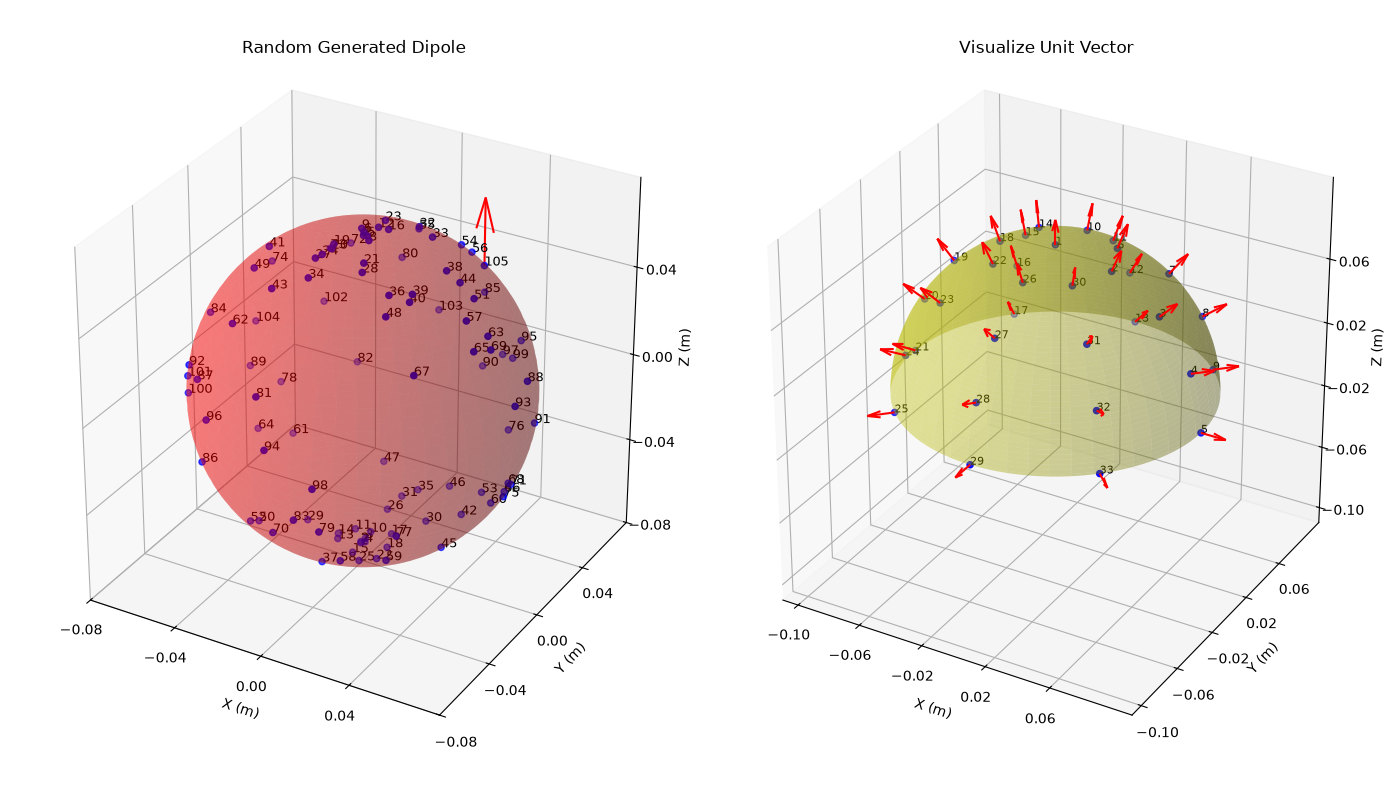

In [4]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 8),
    subplot_kw={'projection': '3d'}
)

visualize_dipole(rq_x, rq_y, rq_z, q_0, radius=R0, ax=axes[0])

visualize_sensors_unit_vectors(r_x, r_y, r_z, er_x, er_y, er_z, radius=R3, ax=axes[1])

plt.tight_layout()
plt.show()

### Calculate and save Lead Field Matrix

In [9]:
# Initialize the MEG lead field matrix G
G = np.zeros((m, 3*n))  # m sensors, 3n dipole components (x, y, z)

for i in range(m):  # loop over all sensors
    for j in range(n):  # loop over all dipoles
        a_ij = Calc_G(er[i], r[i], rq[j])  # returns 3D vector
        G[i, j*3:(j+1)*3] = a_ij

np.savez(data_dir / "MEG_Lead_Field.npz", G = G)

print("MEG Lead field matrix shape:", G.shape)

MEG Lead field matrix shape: (33, 315)


In [10]:
# Initialize the EEG lead field matrix L
L = np.zeros((m, 3*n))  # m sensors, 3n dipole components (x, y, z)

for i in range(m):  # loop over all sensors
    for j in range(n):  # loop over all dipoles
        L_temp = Calc_L(theta_s[i], phi_s[i], r_d[j], theta_d[j], phi_d[j], R3, sg1, sg2, R1, R2, sigma)
        L[i, 3*j:3*j+3] = L_temp  # place L_temp into correct columns

np.savez(data_dir / "EEG_Lead_Field.npz", L = L)
print("EEG Lead field matrix shape:", L.shape)

EEG Lead field matrix shape: (33, 315)


#### Visiualize G[:, 75]

(33,)
(33,)


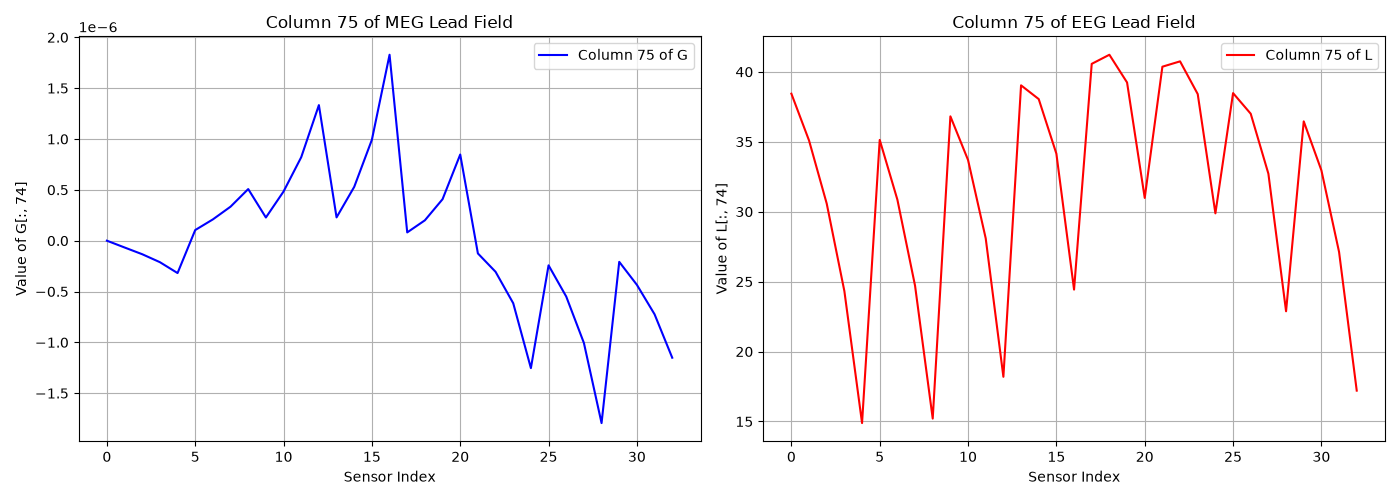

In [11]:
G_column_75 = G[:, 74]
print(G_column_75.shape)

L_column_75 = L[:, 74]
print(L_column_75.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: MEG lead-field
axes[0].plot(G_column_75, color='blue', label='Column 75 of G')
axes[0].set_xlabel('Sensor Index')
axes[0].set_ylabel('Value of G[:, 74]')
axes[0].set_title('Column 75 of MEG Lead Field')
axes[0].grid(True)
axes[0].legend()

# Subplot 2: EEG lead-field
axes[1].plot(L_column_75, color='red', label='Column 75 of L')
axes[1].set_xlabel('Sensor Index')
axes[1].set_ylabel('Value of L[:, 74]')
axes[1].set_title('Column 75 of EEG Lead Field')
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show() 


### Calculate the radial magnetic flux density (Br) at each sensor for single dipole

In [12]:
# MEG Lead field for this single dipole: one row per sensor
G_single = np.zeros((m, 3))
for i in range(m):
    G_single[i] = Calc_G(er[i], r[i], rq_0)   

B_r = np.dot(G_single, q_0)  # shape (33,), in tesla

print(B_r.shape)
np.savez(data_dir / "MEG_Measurements.npz", B_r = B_r)

# EEG Lead field for this single dipole: one row per sensor
L_single = np.zeros((m, 3))
for i in range(m):
    L_single[i] = Calc_L(theta_s[i], phi_s[i],
                         r_d[104], theta_d[104], phi_d[104],
                         R3, sg1, sg2, R1, R2, sigma)

V = np.dot(L_single, q_0)                     # shape (m,)
V = V - V.mean()                      # average reference
print(V.shape)
np.savez(data_dir / "EEG_Measurements.npz", V = V)

(33,)
(33,)


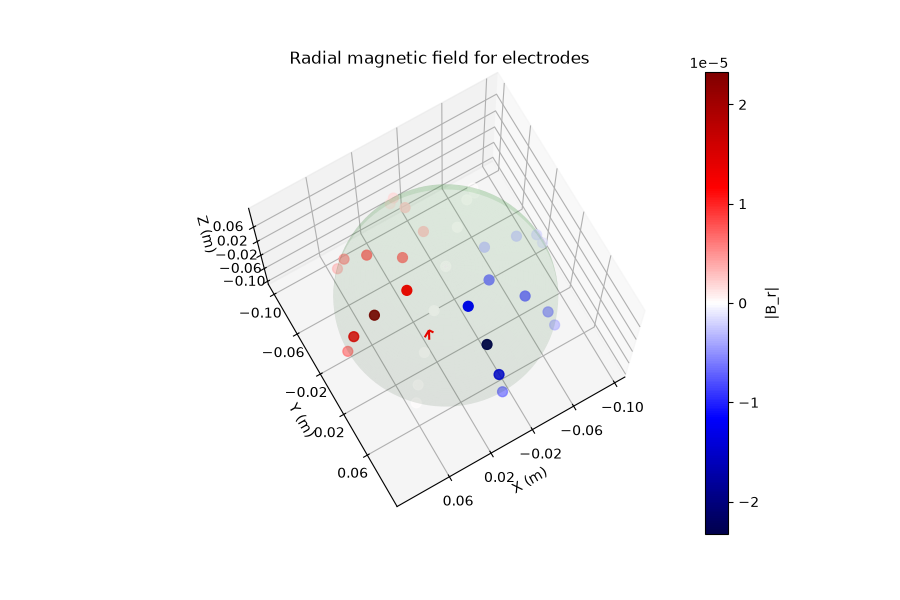

In [13]:
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
plt.title('Radial magnetic field for electrodes') 

# Set size of each axis
ax.set_box_aspect([1, 1, 1])  # This will make the axes equally spaced
ax.set_xlim([-0.11, 0.11])
ax.set_ylim([-0.11, 0.11])
ax.set_zlim([-0.11, 0.11])

# Set the grid grading for each axis
ax.set_xticks(np.arange(-0.1, 0.1, 0.04))
ax.set_yticks(np.arange(-0.1, 0.1, 0.04))
ax.set_zticks(np.arange(-0.1, 0.1, 0.04))

Bmin = np.min(B_r)
Bmax = np.max(B_r)

# Plotting scatter with actual values
import matplotlib.colors as mcolors

norm = mcolors.TwoSlopeNorm(vmin=Bmin, vcenter=0, vmax=Bmax)

scatter = ax.scatter(
    r_x, r_y, r_z,
    c=B_r,
    cmap='seismic',
    norm=norm,
    s=50
)

# Adding color bar
cbar = plt.colorbar(scatter)
cbar.set_label('|B_r|')

ax.quiver(rq_x[104], rq_y[104], rq_z[104], q_0[0], q_0[1], q_0[2], color='r', length=0.03,
          normalize=True, arrow_length_ratio=0.5)

radius = 0.09
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi / 2, 100)

x_hemisphere = radius * np.outer(np.cos(u), np.sin(v))
y_hemisphere = radius * np.outer(np.sin(u), np.sin(v))
z_hemisphere = radius * np.outer(np.ones(np.size(u)), np.cos(v))

ax.plot_surface(x_hemisphere, y_hemisphere, z_hemisphere, color='g', alpha=0.1)

ax.set_xlabel('X (m)')
ax.set_ylabel('Y (m)')
ax.set_zlabel('Z (m)')


ax.view_init(elev=75, azim=60) # Diagonal view

plt.show()

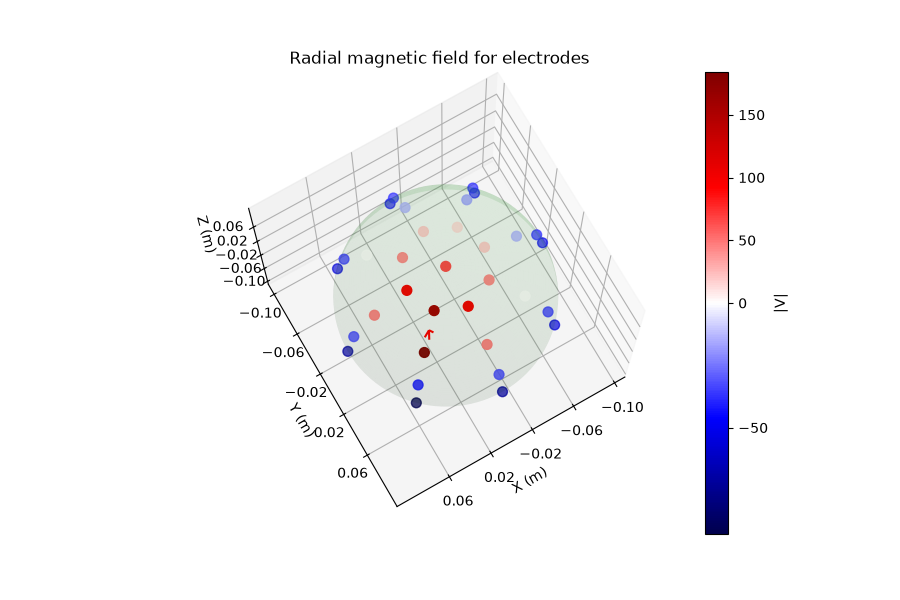

In [14]:
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
plt.title('Radial magnetic field for electrodes') 

# Set size of each axis
ax.set_box_aspect([1, 1, 1])  # This will make the axes equally spaced
ax.set_xlim([-0.11, 0.11])
ax.set_ylim([-0.11, 0.11])
ax.set_zlim([-0.11, 0.11])

# Set the grid grading for each axis
ax.set_xticks(np.arange(-0.1, 0.1, 0.04))
ax.set_yticks(np.arange(-0.1, 0.1, 0.04))
ax.set_zticks(np.arange(-0.1, 0.1, 0.04))

Bmin = np.min(V)
Bmax = np.max(V)

# Plotting scatter with actual values
import matplotlib.colors as mcolors

norm = mcolors.TwoSlopeNorm(vmin=Bmin, vcenter=0, vmax=Bmax)

scatter = ax.scatter(
    r_x, r_y, r_z,
    c=V,
    cmap='seismic',
    norm=norm,
    s=50
)

# Adding color bar
cbar = plt.colorbar(scatter)
cbar.set_label('|V|')

ax.quiver(rq_x[104], rq_y[104], rq_z[104], q_0[0], q_0[1], q_0[2], color='r', length=0.03,
          normalize=True, arrow_length_ratio=0.5)

radius = 0.09
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi / 2, 100)

x_hemisphere = radius * np.outer(np.cos(u), np.sin(v))
y_hemisphere = radius * np.outer(np.sin(u), np.sin(v))
z_hemisphere = radius * np.outer(np.ones(np.size(u)), np.cos(v))

ax.plot_surface(x_hemisphere, y_hemisphere, z_hemisphere, color='g', alpha=0.1)

ax.set_xlabel('X (m)')
ax.set_ylabel('Y (m)')
ax.set_zlabel('Z (m)')


ax.view_init(elev=75, azim=60) # Diagonal view

plt.show()